<a href="https://colab.research.google.com/github/devPartho3/Mern-Stack-Web-Dev-Marathon-/blob/main/Energy_Demand_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
data=pd.read_csv('/content/TimeSeries_TotalSolarGen_and_Load_IT_2016.csv')
data.head(5)

,utc_timestamp,IT_load_new,IT_solar_generation
0,2016-01-01T00:00:00Z,21665.0,1
1,2016-01-01T01:00:00Z,20260.0,0
2,2016-01-01T02:00:00Z,19056.0,0
3,2016-01-01T03:00:00Z,18407.0,0
4,2016-01-01T04:00:00Z,18425.0,0


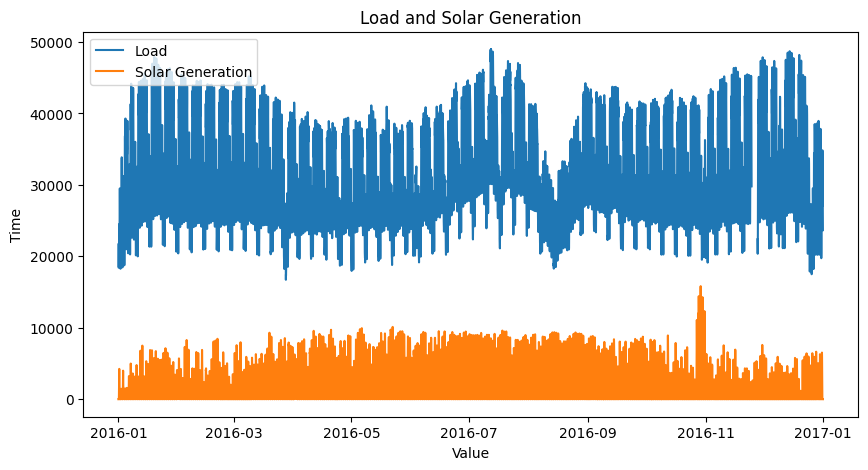

In [3]:
data['utc_timestamp']=pd.to_datetime(data['utc_timestamp'])
data.head(5)

plt.figure(figsize=(10,5))
plt.plot(data['utc_timestamp'],data['IT_load_new'],label='Load')
plt.plot(data['utc_timestamp'],data['IT_solar_generation'],label='Solar Generation')
plt.xlabel('Value')
plt.ylabel('Time')
plt.title('Load and Solar Generation')
plt.legend()
plt.show()




In [4]:
#handle missing values
data.isnull().sum()
data.dropna(inplace=True)
data.isnull().sum()

#

,0
utc_timestamp,0
IT_load_new,0
IT_solar_generation,0


In [6]:
from statsmodels.tsa.stattools import adfuller

# fill missing values with forward fill
data['IT_load_new'].fillna(method='ffill', inplace=True)
data['IT_solar_generation'].fillna(method='ffill', inplace=True)

# check missing values again
print('Missing values after filling: ')
print(data.isnull().sum())

# Define the ADF test function
def adf_test(series):
    result = adfuller(series.dropna())
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    for key, value in result[4].items():
        print(f'Critical Value ({key}): {value}')

# Perform augmented dickey fuller test
print('\nAugmented dickey fuller test for IT_load_new:')
adf_test(data['IT_load_new'])

print('\nAugmented dickey fuller test for IT_solar_generation:')
adf_test(data['IT_solar_generation'])

/tmp/ipykernel_1263/3063690444.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['IT_load_new'].fillna(method='ffill', inplace=True)
/tmp/ipykernel_1263/3063690444.py:4: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data['IT_load_new'].fillna(method='ffill', inplace=True)
/tmp/ipykernel_1263/3063690444.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace meth

Missing values after filling: 
utc_timestamp          0
IT_load_new            0
IT_solar_generation    0
dtype: int64

Augmented dickey fuller test for IT_load_new:


/tmp/ipykernel_1263/3063690444.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


ADF Statistic: -11.887159502378132
p-value: 5.985916305535662e-22
Critical Value (1%): -3.4311041199290315
Critical Value (5%): -2.861873270539268
Critical Value (10%): -2.5669473949551955

Augmented dickey fuller test for IT_solar_generation:
ADF Statistic: -5.755084912509391
p-value: 5.845003815121364e-07
Critical Value (1%): -3.431104032973037
Critical Value (5%): -2.861873232115414
Critical Value (10%): -2.566947374501906


/tmp/ipykernel_1263/3063690444.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            IT_load_new   No. Observations:                 8712
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -74630.916
Date:                Tue, 13 Oct 2026   AIC                         149267.832
Time:                        13:56:17   BIC                         149289.049
Sample:                             0   HQIC                        149275.063
                               - 8712                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6349      0.009     74.444      0.000       0.618       0.652
ma.L1          0.3886      0.012     32.807      0.000       0.365       0.412
sigma2      1.652e+06   1.97e+04     83.900      0.0

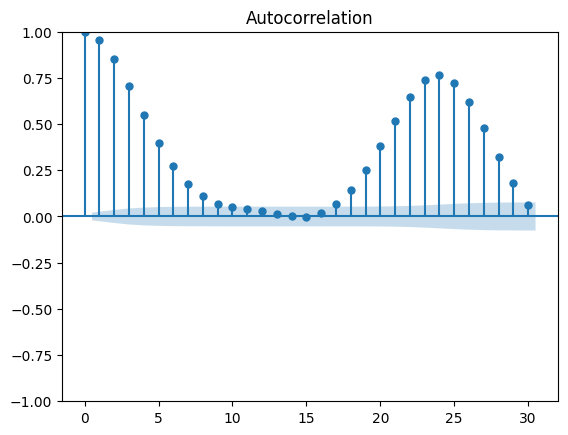

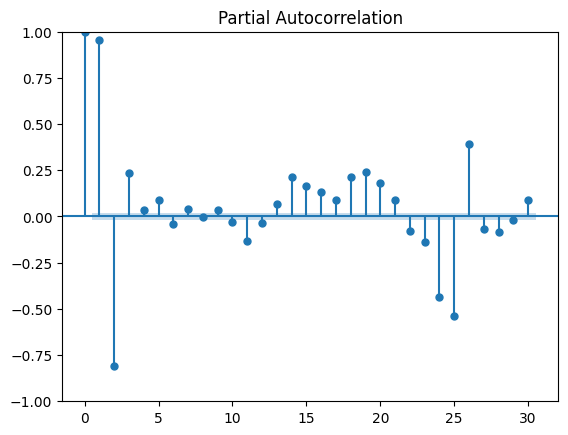

In [8]:
#build arima model for 'IT_LOAD_NEW'

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

model=ARIMA(data['IT_load_new'],order=(1,1,1))
model_fit=model.fit()
print(model_fit.summary())

#plot acf and pacf
plot_acf(data['IT_load_new'],lags=30)
plot_pacf(data['IT_load_new'],lags=30)
plt.show()

In [11]:
from sklearn.metrics import mean_squared_error
from math import sqrt

#split data into training and testing

train_size=int(len(data)*0.8)
train,test=data[0:train_size],data[train_size:len(data)]
print(len(train),len(test))

#fit the ARIMA model

model=ARIMA(train['IT_load_new'],order=(2,0,2))
model_fit=model.fit()


#Make predictions on the test set (removing the deprecated typ argument)

predictions=model_fit.predict(start=len(train),end=len(train)+len(test)-1)

#calculate the RMSE

rmse=sqrt(mean_squared_error(test['IT_load_new'],predictions))
print(f'RMSE: {rmse}')

6969 1743
RMSE: 7827.567327967573


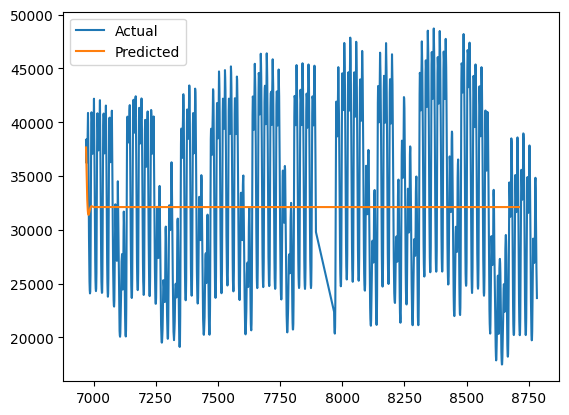

In [12]:
#plot actual and predicted values

plt.plot(test['IT_load_new'],label='Actual')
plt.plot(predictions,label='Predicted')
plt.legend()
plt.show()